# EDA: IBM Telco Customer Churn

Цель ноутбука: понять данные перед построением моделей. Обучение и оценка здесь не выполняются,
они запускаются из командной строки.

Вопросы:
1. Есть ли пропуски и корректны ли типы?
2. Как распределены признаки?
3. Какие признаки связаны с оттоком?
4. Что не так с `TotalCharges`?
5. Почему `customerID` не должен быть признаком?

In [1]:
import os, sys, json
from pathlib import Path
# Ноутбук лежит в notebooks/, корень проекта на уровень выше.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from churn.data import (load_raw, validate_schema, clean_data, parse_total_charges,
                        download_data, NUMERIC_FEATURES, CATEGORICAL_FEATURES, FEATURES)

FIG_DIR = Path("reports/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
raw = load_raw(download_data())
validate_schema(raw)
raw.shape

(7043, 21)

## 1. Типы и пропуски

In [2]:
pd.DataFrame({"dtype": raw.dtypes.astype(str), "n_unique": raw.nunique(),
              "n_missing": raw.isna().sum()})

,dtype,n_unique,n_missing
customerID,str,7043,0
gender,str,2,0
SeniorCitizen,int64,2,0
Partner,str,2,0
Dependents,str,2,0
tenure,int64,73,0
PhoneService,str,2,0
MultipleLines,str,3,0
InternetService,str,3,0
OnlineSecurity,str,3,0


Формальных пропусков (NaN) нет, но `TotalCharges` прочитан как строка, хотя это сумма денег.
Значит, в столбце есть нечисловые значения. Ищем их.

In [3]:
total_num = parse_total_charges(raw["TotalCharges"])
bad = raw[total_num.isna()]
print("Нечисловых значений TotalCharges:", len(bad), "| уникальные:", bad["TotalCharges"].unique().tolist())
bad[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]]

Нечисловых значений TotalCharges: 11 | уникальные: [' ']


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


## 2. Исследование TotalCharges

Все 11 пустых значений (строка из одного пробела) приходятся на клиентов с `tenure == 0`,
и других клиентов с `tenure == 0` нет. Это новые клиенты, которые ещё не прошли ни одного
расчётного периода. Логичное значение для них: 0. Проверим, что `TotalCharges` действительно
близок к `tenure * MonthlyCharges`.

In [4]:
print("Клиентов с tenure == 0:", int((raw["tenure"] == 0).sum()))
ok = total_num.notna()
approx = raw.loc[ok, "tenure"] * raw.loc[ok, "MonthlyCharges"]
rel_err = (total_num[ok] - approx) / total_num[ok]
print("Относительное отклонение TotalCharges от tenure*MonthlyCharges:")
print(rel_err.describe().round(4))
print("Корреляции:")
print(pd.concat([total_num.rename("TotalCharges"), raw[["tenure", "MonthlyCharges"]]], axis=1).corr().round(3))

Клиентов с tenure == 0: 11
Относительное отклонение TotalCharges от tenure*MonthlyCharges:
count    7032.0000
mean       -0.0023
std         0.0513
min        -0.4506
25%        -0.0209
50%         0.0000
75%         0.0192
max         0.3645
dtype: float64
Корреляции:
                TotalCharges  tenure  MonthlyCharges
TotalCharges           1.000   0.826           0.651
tenure                 0.826   1.000           0.248
MonthlyCharges         0.651   0.248           1.000


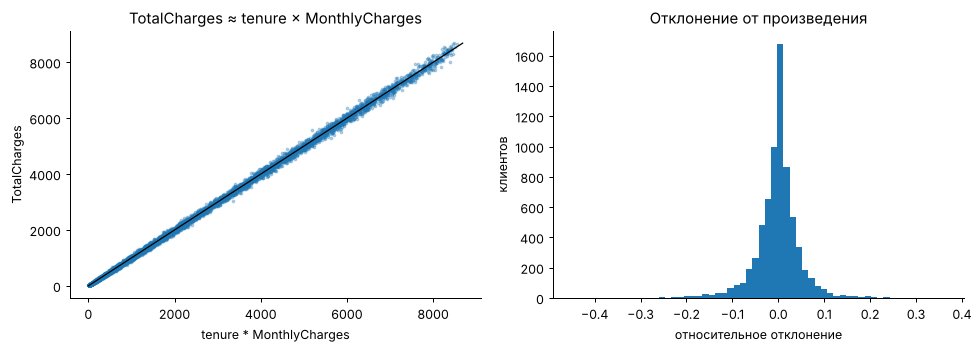

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(approx, total_num[ok], s=4, alpha=0.3)
lim = [0, total_num.max()]
axes[0].plot(lim, lim, color="black", lw=1)
axes[0].set(xlabel="tenure * MonthlyCharges", ylabel="TotalCharges", title="TotalCharges ≈ tenure × MonthlyCharges")
axes[1].hist(rel_err, bins=60)
axes[1].set(xlabel="относительное отклонение", ylabel="клиентов", title="Отклонение от произведения")
fig.tight_layout(); fig.savefig(FIG_DIR / "total_charges.png"); plt.show()

**Вывод по TotalCharges.** Столбец почти полностью определяется произведением
`tenure × MonthlyCharges` (медианное отклонение 0, разброс около ±5% из-за изменения тарифа
во времени), корреляция с `tenure` 0.83. Новой информации он добавляет мало, но и вреда
не приносит; оставляем его, а для линейной модели учитываем мультиколлинеарность (регуляризация).
Пустые значения заменяются на 0 правилом в `churn.data.clean_data`: оно построчное и не использует
статистик выборки, поэтому утечки не создаёт. Импьютер в Pipeline оставлен на случай
необъяснимых пропусков в новых данных.

## 3. Идентификатор клиента

In [6]:
print("Уникальных customerID:", raw["customerID"].nunique(), "из", len(raw))
print(raw["customerID"].head().tolist())

Уникальных customerID: 7043 из 7043
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU']


`customerID` уникален для каждой строки и не несёт смысла о поведении клиента. Если подать его
модели, она сможет только запомнить конкретных клиентов, что даст переобучение и, при пересечении
id между выборками, утечку. Поэтому `customerID` исключён из `FEATURES` и используется только для
отслеживания разбиений и предсказаний.

In [7]:
df = clean_data(raw)
assert "customerID" not in FEATURES
print("Признаков:", len(FEATURES))
print("Доля оттока:", round(df["Churn"].mean(), 4))

Признаков: 19
Доля оттока: 0.2654


## 4. Распределения числовых признаков и связь с оттоком

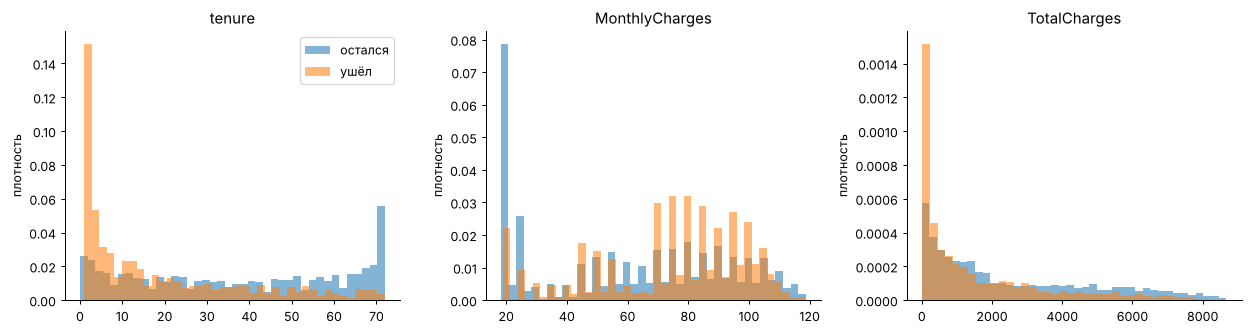

,tenure,MonthlyCharges,TotalCharges
Churn,,,
0,38.0,64.43,1679.52
1,10.0,79.65,703.55


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, NUMERIC_FEATURES):
    for label, name in [(0, "остался"), (1, "ушёл")]:
        ax.hist(df.loc[df["Churn"] == label, col], bins=40, alpha=0.55, density=True, label=name)
    ax.set(title=col, ylabel="плотность")
axes[0].legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "numeric_by_churn.png"); plt.show()
df.groupby("Churn")[NUMERIC_FEATURES].median().round(2)

In [9]:
bins = [-1, 6, 12, 24, 48, 72]
labels = ["0-6", "7-12", "13-24", "25-48", "49-72"]
df.groupby(pd.cut(df["tenure"], bins=bins, labels=labels), observed=True)["Churn"].agg(["mean", "size"]).round(3)

,mean,size
tenure,,
0-6,0.529,1481
7-12,0.359,705
13-24,0.287,1024
25-48,0.204,1594
49-72,0.095,2239


Уходят в основном недавние клиенты: в первые полгода отток около половины, после четырёх лет
единицы процентов. Ушедшие платят больше в месяц (медиана около 80 против 64), а их `TotalCharges`
меньше, потому что стаж короче.

## 5. Категориальные признаки и отток

In [10]:
rates = []
for col in CATEGORICAL_FEATURES + ["SeniorCitizen"]:
    g = df.groupby(col)["Churn"].agg(["mean", "size"])
    for value, row in g.iterrows():
        rates.append({"feature": col, "value": str(value), "churn_rate": row["mean"], "n": int(row["size"])})
rates = pd.DataFrame(rates)
spread = rates.groupby("feature")["churn_rate"].agg(lambda s: s.max() - s.min()).sort_values(ascending=False)
spread.round(3).rename("разница max-min доли оттока")

feature
Contract            0.399
InternetService     0.345
OnlineSecurity      0.344
TechSupport         0.342
OnlineBackup        0.325
DeviceProtection    0.317
PaymentMethod       0.300
StreamingMovies     0.263
StreamingTV         0.261
SeniorCitizen       0.181
PaperlessBilling    0.172
Dependents          0.158
Partner             0.133
MultipleLines       0.037
PhoneService        0.018
gender              0.008
Name: разница max-min доли оттока, dtype: float64

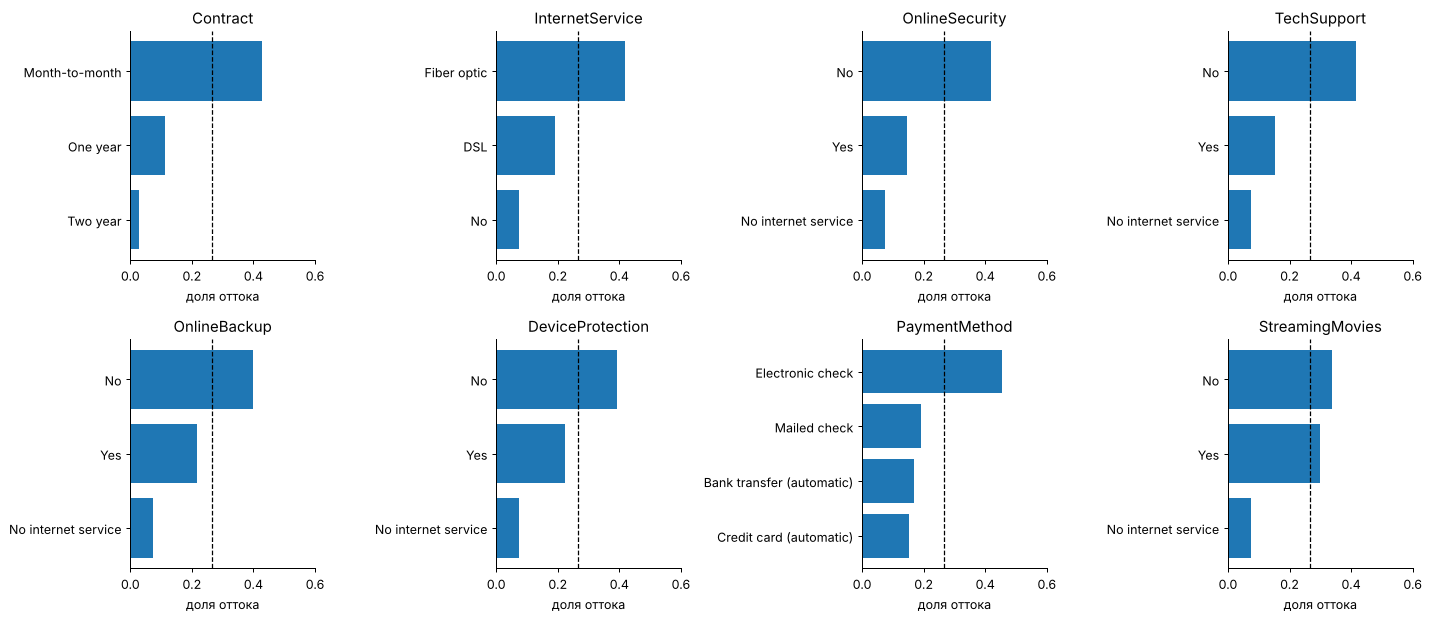

In [11]:
top = spread.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), top):
    sub = rates[rates["feature"] == col].sort_values("churn_rate")
    ax.barh(sub["value"], sub["churn_rate"])
    ax.axvline(df["Churn"].mean(), color="black", lw=1, ls="--")
    ax.set(title=col, xlabel="доля оттока", xlim=(0, 0.6))
fig.tight_layout(); fig.savefig(FIG_DIR / "categorical_churn_rate.png"); plt.show()

Наиболее связаны с оттоком тип контракта (помесячный против двухлетнего), отсутствие
`OnlineSecurity`/`TechSupport`, оптоволоконный интернет и оплата электронным чеком.
`gender` и `PhoneService` почти не влияют. Значение `No internet service` повторяется в шести
столбцах: оно полностью определяется `InternetService == "No"`, это структурная зависимость между
признаками, а не утечка.

In [12]:
no_inet = df["InternetService"] == "No"
dependent = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
print(all(((df[c] == "No internet service") == no_inet).all() for c in dependent))
print(((df["MultipleLines"] == "No phone service") == (df["PhoneService"] == "No")).all())

True
True


## 6. Итоги EDA

In [13]:
summary = {
    "n_rows": int(len(raw)),
    "churn_rate": round(float(df["Churn"].mean()), 4),
    "nan_in_raw": int(raw.isna().sum().sum()),
    "total_charges_blank": int(len(bad)),
    "total_charges_blank_all_tenure_zero": bool((bad["tenure"] == 0).all()),
    "total_charges_rule": "blank TotalCharges with tenure == 0 -> 0.0",
    "corr_total_charges_tenure": round(float(df[["TotalCharges", "tenure"]].corr().iloc[0, 1]), 3),
    "excluded_columns": ["customerID"],
    "churn_rate_spread_by_feature": spread.round(3).to_dict(),
}
Path("results").mkdir(exist_ok=True)
Path("results/eda_summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False) + "\n")
summary

{'n_rows': 7043,
 'churn_rate': 0.2654,
 'nan_in_raw': 0,
 'total_charges_blank': 11,
 'total_charges_blank_all_tenure_zero': True,
 'total_charges_rule': 'blank TotalCharges with tenure == 0 -> 0.0',
 'corr_total_charges_tenure': 0.826,
 'excluded_columns': ['customerID'],
 'churn_rate_spread_by_feature': {'Contract': 0.399,
  'InternetService': 0.345,
  'OnlineSecurity': 0.344,
  'TechSupport': 0.342,
  'OnlineBackup': 0.325,
  'DeviceProtection': 0.317,
  'PaymentMethod': 0.3,
  'StreamingMovies': 0.263,
  'StreamingTV': 0.261,
  'SeniorCitizen': 0.181,
  'PaperlessBilling': 0.172,
  'Dependents': 0.158,
  'Partner': 0.133,
  'MultipleLines': 0.037,
  'PhoneService': 0.018,
  'gender': 0.008}}

- Пропусков в виде NaN нет; единственная проблема типов: `TotalCharges`, 11 пустых строк у новых клиентов.
- Классы несбалансированы (26.5% оттока), поэтому кроме ROC-AUC нужны PR-AUC, F1 и подбор порога.
- Сильные сигналы: стаж, тип контракта, интернет-услуги, способ оплаты, месячный платёж.
- `customerID` исключён из признаков.
- Для деревьев числовые признаки не нужно масштабировать; для логистической регрессии нужны
  масштабирование и one-hot кодирование.
- Явных признаков из будущего (например, причины ухода) в этой версии датасета нет; подробнее
  утечку разберём на этапе анализа ошибок.